# Lab 7 — Filters Applied to Salt & Pepper Image

In [1]:
import base64
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rc("text", usetex=False)


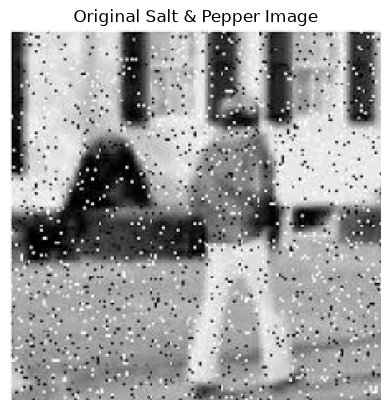

In [2]:
# Embedded source image: salt&Pepper.jpg
image_base64 = "..."
original_img = cv2.imdecode(np.frombuffer(base64.b64decode(image_base64), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
if original_img is None:
    raise ValueError("Could not decode the embedded image")
img = original_img.copy()
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Salt & Pepper Image")
plt.axis("off")
plt.show()


## Part A — Laplacian Filter


## Apply Laplacian Filter on Image to get Sharp Image

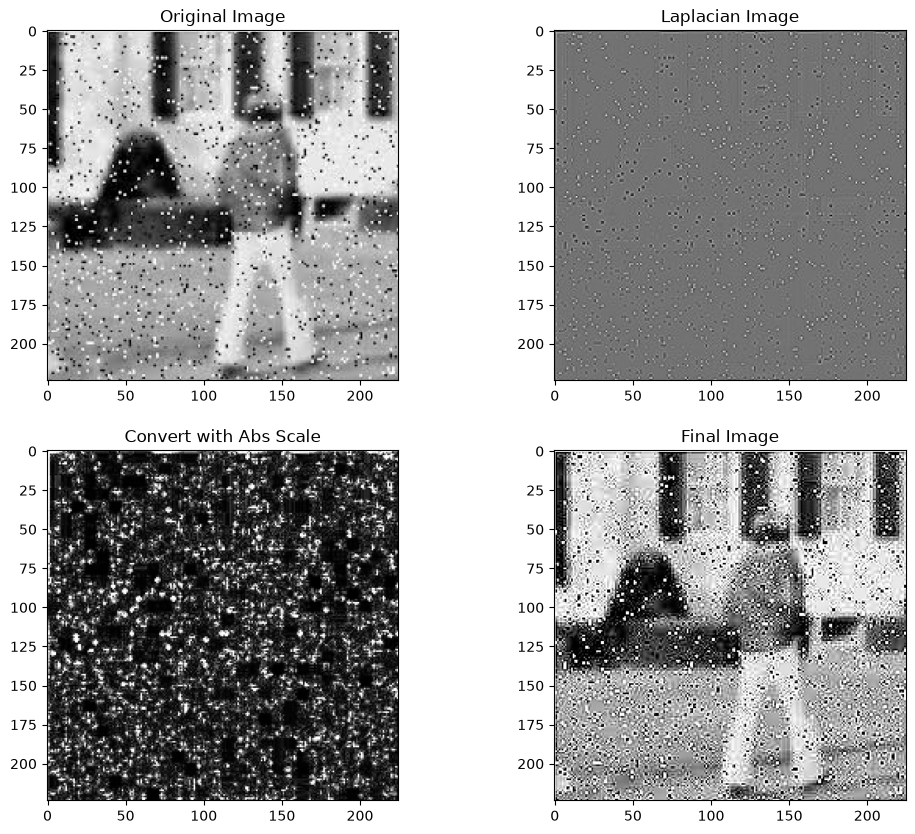

In [3]:
# ================ ( Laplacian Filter ) ===================
# 0. Image file path
# The source image is embedded above.
# 1. Load image and convert to grayscale
img = original_img.copy()

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: Detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)
# 3. Apply the filter using filter2D
# -1 indicates the output image will have the same depth as the source
# However, for Laplacian, use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)
# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)
finalImage = np.clip(img.astype(np.float64) - laplacian_manual, 0, 255).astype(np.uint8)
# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()


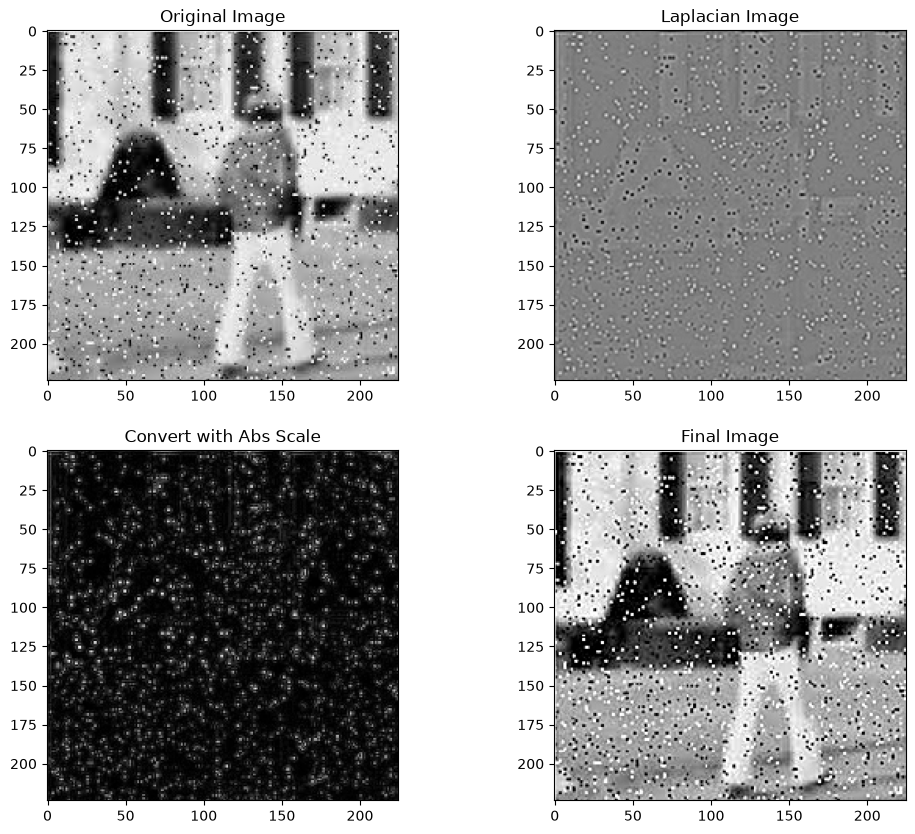

In [4]:
# ================== ( Laplacian Filter ) ===============
# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)
# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)
# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)
# 4. Subtract the signed Laplacian and clip to the valid range
finalImage2 = np.clip(img.astype(np.float64) - laplacian, 0, 255).astype(np.uint8)
# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()

## Part B — Mathematical and Statistical Filters


In [5]:
img = original_img.copy()

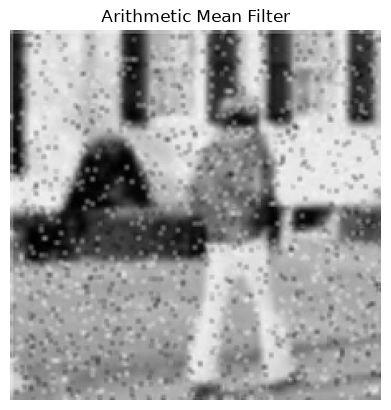

In [6]:
# --- METHOD 1: Using Built-in OpenCV function ---

# 2. Apply Arithmetic Mean Filter (using a 5x5 blur window)
# The larger the numbers in (3, 3), the smoother the image becomes.,
# you can change kernel size to (5,5), (7,7) etc.
filtered_img = cv2.blur(img, (3, 3))

plt.imshow(filtered_img, cmap="gray", vmin=0, vmax=255)
plt.title("Arithmetic Mean Filter")
plt.axis("off")
plt.show()

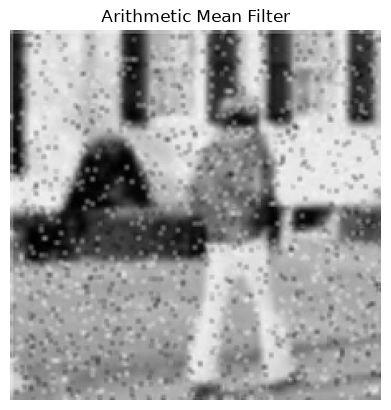

In [7]:
# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(img, -1, kernel)

plt.imshow(arithmetic_mean_manual, cmap="gray", vmin=0, vmax=255)
plt.title("Arithmetic Mean Filter")
plt.axis("off")
plt.show()

## **Geometric Means**

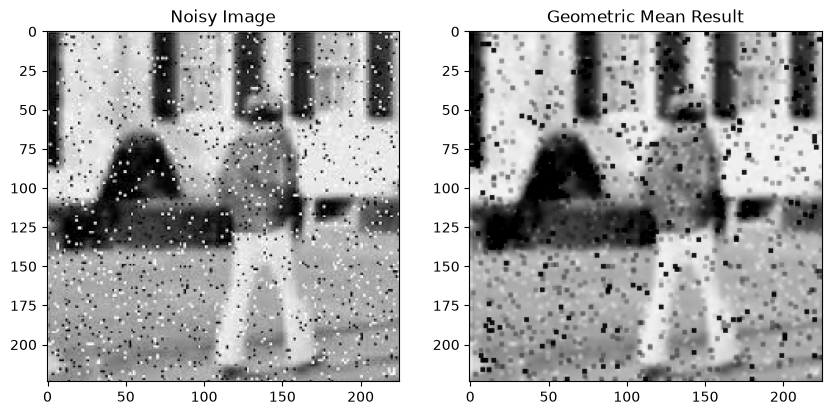

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = img

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('Geometric Mean Result')
plt.show()


## **Harmonic Means Filter**

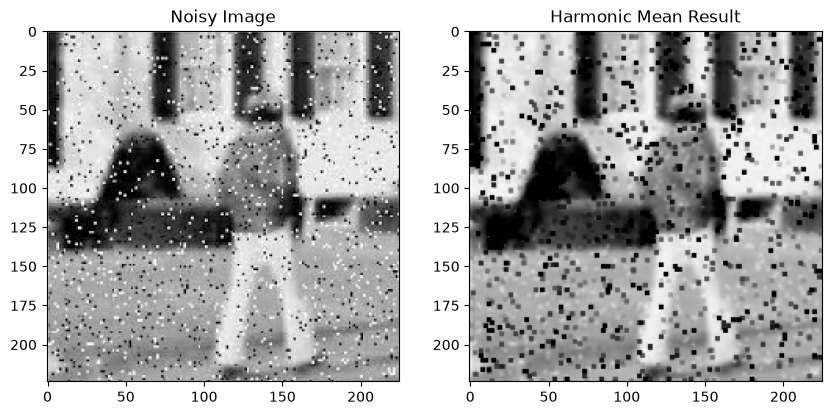

In [9]:

def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window and divide by window size
    # This is equivalent to applying a standard mean filter to the reciprocal image
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = img

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img, cmap='gray'), plt.title('Harmonic Mean Result')
plt.show()


## **Contra - Harmonic Mean Filter**

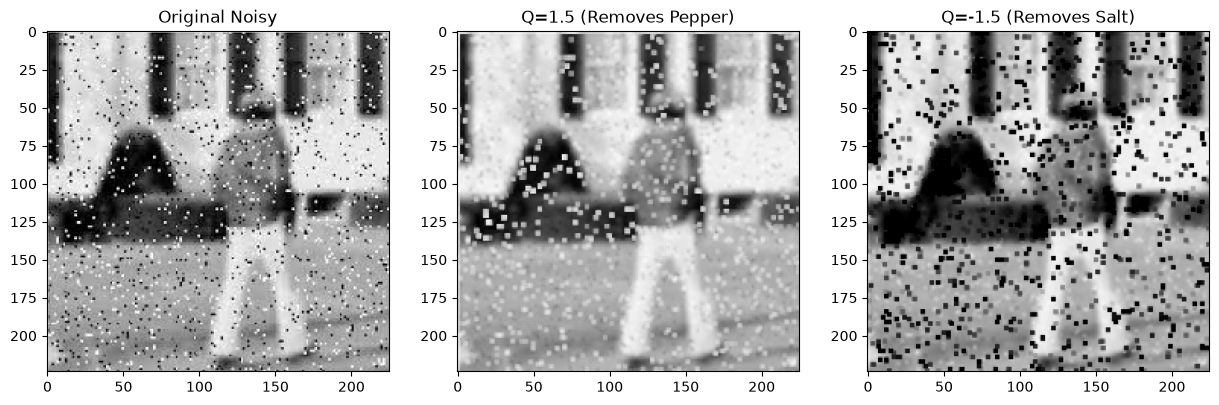

In [11]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6
    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)
    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)
    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)
    return np.clip(result, 0, 255).astype(np.uint8)
# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")
noise_img = img
# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)
# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)
#DISPLAY
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(pepper_removed, cmap='gray'), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed, cmap='gray'), plt.title('Q=-1.5 (Removes Salt)')
plt.show()


## **Median Filter**

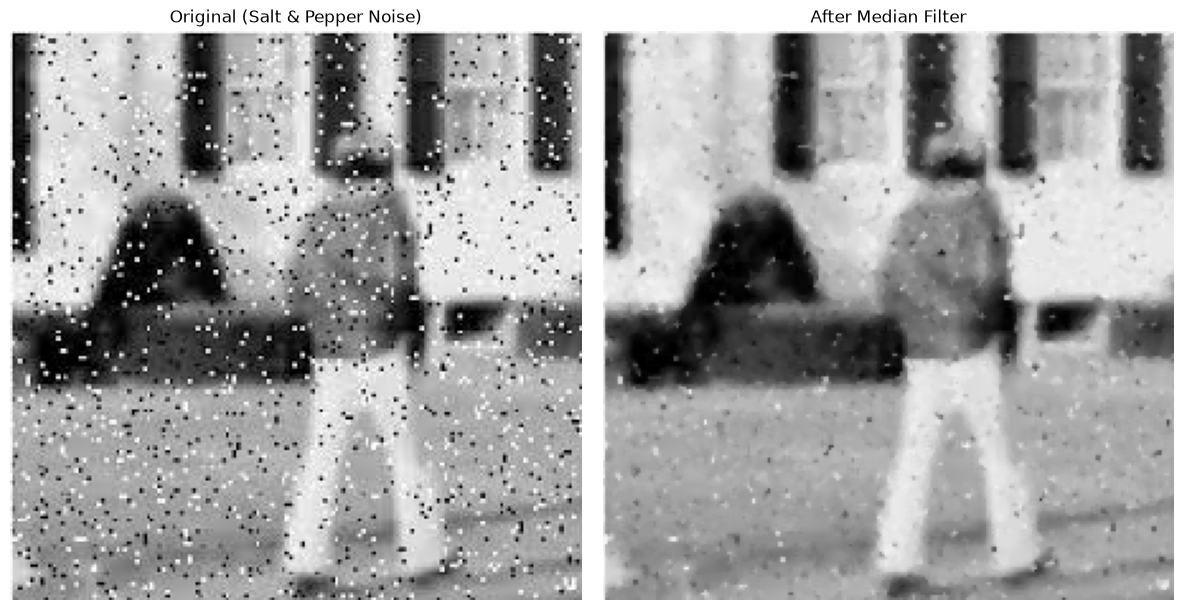

In [12]:
# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")
noise_img = img
# 2. Apply Median Filter
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)
# 3. Compare Results
plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Salt & Pepper Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result, cmap='gray'), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


## **Max and Min Filter**

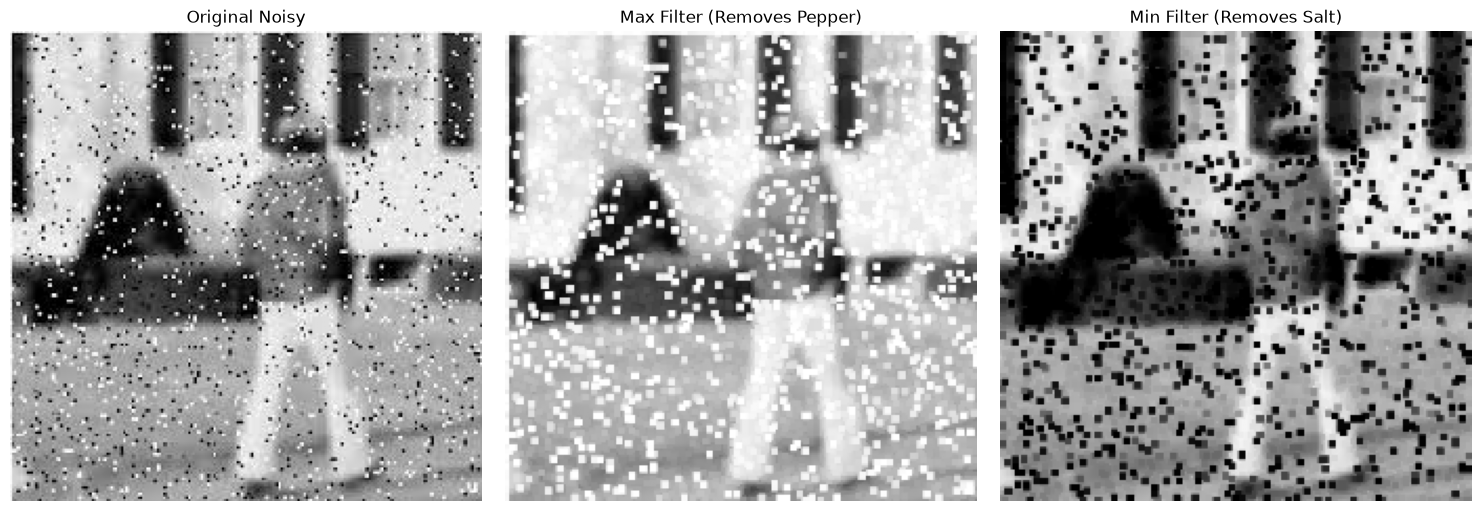

In [13]:

# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")
noise_img = img
# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)
# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood.
max_filter = cv2.dilate(noise_img, kernel)
# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood.
min_filter = cv2.erode(noise_img, kernel)
#Display Results 
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(max_filter, cmap='gray'), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter, cmap='gray'), plt.title('Min Filter (Removes Salt)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## **Mid-Point Filtering**

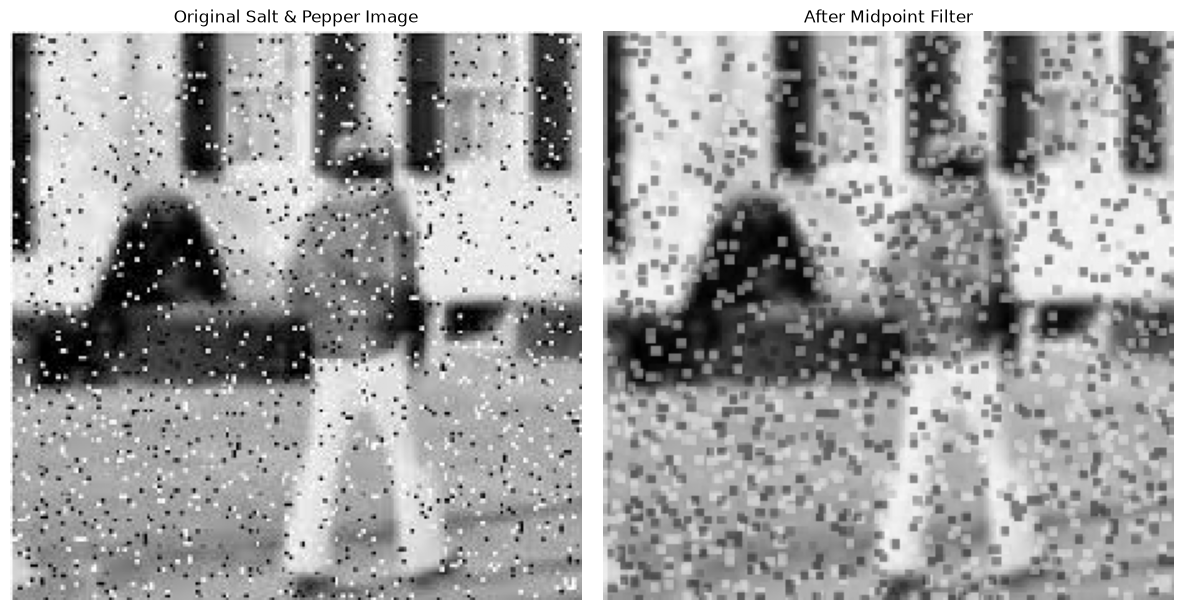

In [14]:
def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)
    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)
    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2
    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)
# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")
noise_img = img
# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)
#Display Results
plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original Salt & Pepper Image'), plt.axis('off')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()
